##Stage 01 — Understand and inspect

In [10]:
# Import Libararies

# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [11]:
# Load the dataset using Pandas

df = pd.read_csv("/content/drive/MyDrive/DataSet/student_performance.csv")


In [12]:
# Display the first five rows
df.head()

,StudyHours,AttendancePct,PreviousScore,FinalMarks
0,6.3,53.1,89.0,85.5
1,3.8,72.9,61.2,58.0
2,6.9,56.5,96.7,68.9
3,5.7,57.6,75.6,62.2
4,1.2,81.6,38.1,53.2


In [13]:
# Shape and column of data
print("Dataset Shape:", df.shape)

# number of rows and columns
print("Rows:    ",df.shape[0])
print("Columns: ",df.shape[1])


# name of columns
print("\nColumn Names:")
print(df.columns)

Dataset Shape: (1008, 4)
Rows:     1008
Columns:  4

Column Names:
Index(['StudyHours', 'AttendancePct', 'PreviousScore', 'FinalMarks'], dtype='object')


In [14]:

# Check all column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   StudyHours     996 non-null    float64
 1   AttendancePct  996 non-null    float64
 2   PreviousScore  998 non-null    float64
 3   FinalMarks     999 non-null    float64
dtypes: float64(4)
memory usage: 31.6 KB


In [15]:

# Find the missing values in each column
df.isnull().sum()

,0
StudyHours,12
AttendancePct,12
PreviousScore,10
FinalMarks,9


In [16]:
# Check whether duplicate rows exist.
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 8


In [17]:
# Generate descriptive statistics for the numerical columns.
df.describe()

,StudyHours,AttendancePct,PreviousScore,FinalMarks
count,996.000000,996.000000,998.000000,999.000000
mean,4.216767,75.388353,64.501703,66.343243
std,2.183448,14.473213,20.255897,13.629633
min,0.500000,50.000000,30.100000,26.100000
25%,2.300000,62.300000,47.125000,56.600000
50%,4.200000,74.750000,64.800000,66.300000
75%,6.200000,88.200000,82.175000,76.000000
max,8.000000,100.000000,100.000000,100.000000


##Stage 2 — Data cleaning





In [18]:
# Remove duplicate rows
df = df.drop_duplicates()

In [19]:
# Remove rows where the target is missing
df = df.dropna(subset=["FinalMarks"])

In [20]:
# Check the cleaned dataset
print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (992, 4)

Missing Values:
StudyHours       12
AttendancePct    12
PreviousScore    10
FinalMarks        0
dtype: int64

Duplicate Rows: 0


##Stage 3 — Exploratory Data Analysis (EDA)

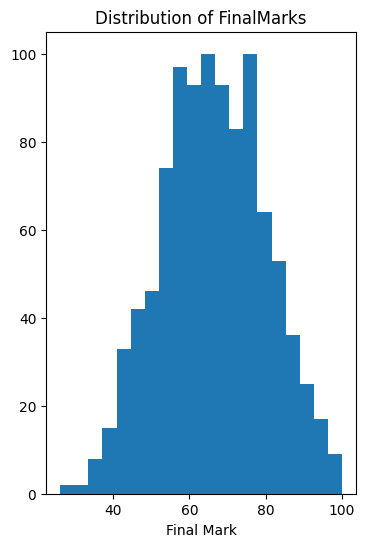

In [21]:
# distribution of FinalMarks Histogram
plt.figure(figsize=(4,6))
plt.hist(df["FinalMarks"], bins=20)
plt.title("Distribution of FinalMarks")
plt.xlabel("Final Mark")
plt.show()

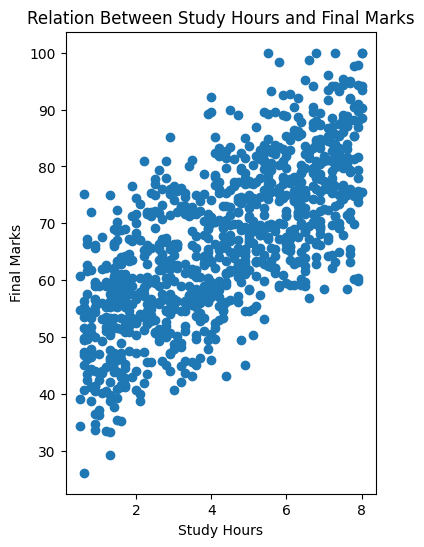

In [22]:
# Scatter plots
plt.figure(figsize= (4,6))
plt.scatter(df["StudyHours"],df["FinalMarks"])
plt.title("Relation Between Study Hours and Final Marks")
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.show()

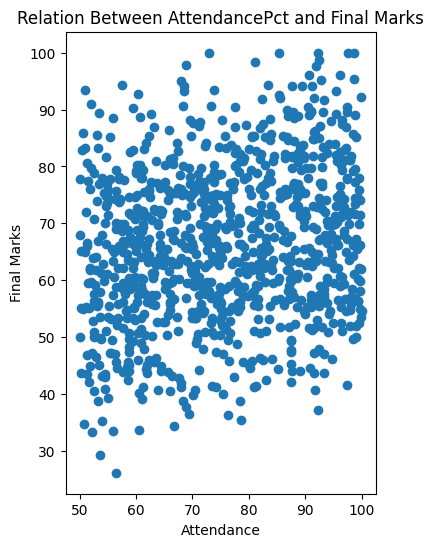

In [23]:
plt.figure(figsize= (4,6))
plt.scatter(df["AttendancePct"],df["FinalMarks"])
plt.title("Relation Between AttendancePct and Final Marks")
plt.xlabel("Attendance")
plt.ylabel("Final Marks")
plt.show()

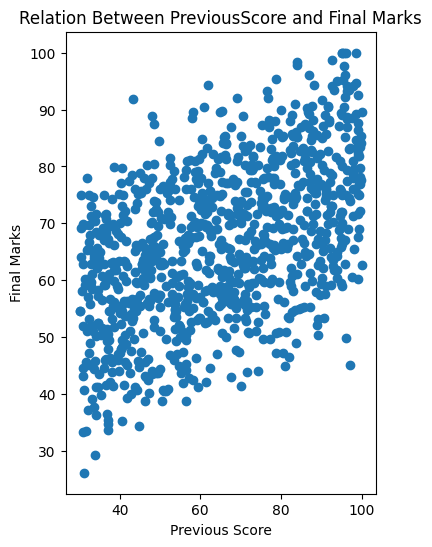

In [24]:
plt.figure(figsize= (4,6))
plt.scatter(df["PreviousScore"],df["FinalMarks"])
plt.title("Relation Between PreviousScore and Final Marks")
plt.xlabel("Previous Score")
plt.ylabel("Final Marks")
plt.show()

Correlation Matrix and Heatmap

In [25]:
# Correlation Matrix for the Entire DataFrame
df_corr = df.corr()
df_corr

,StudyHours,AttendancePct,PreviousScore,FinalMarks
StudyHours,1.000000,-0.003268,-0.005037,0.706967
AttendancePct,-0.003268,1.000000,-0.033052,0.201005
PreviousScore,-0.005037,-0.033052,1.000000,0.510605
FinalMarks,0.706967,0.201005,0.510605,1.000000


In [26]:
# Correlation Between Two Specific Columns
correlation = df["StudyHours"].corr(df["FinalMarks"])
print("Correlation between Study Hours and Final Marks:", correlation)

Correlation between Study Hours and Final Marks: 0.7069674950972159


In [27]:
# correlation matrix for numerical columns

Seaborn heatmap

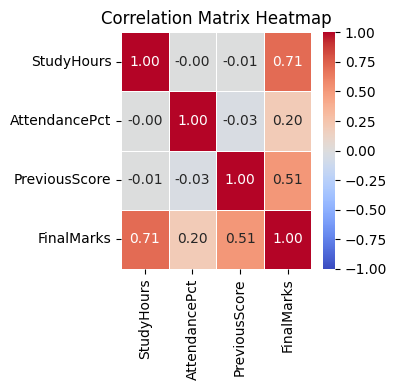

In [28]:
# Seaborn heatmap
plt.figure(figsize=(4,4))
sns.heatmap(df_corr, annot = True, cmap="coolwarm", fmt=".2f",
vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix Heatmap")
plt.tight_layout()
plt.show()

##Stage 4 — Separate Features (X) and Target (y)

In [29]:
# To split data into training and testing sets

X = df[["StudyHours", "AttendancePct", "PreviousScore"]]
y = df["FinalMarks"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.3, random_state=40)


print(f"Training set size: {X_train.shape[0]} rows")
print(f"Testing set size: {X_test.shape[0]} rows")

Training set size: 694 rows
Testing set size: 298 rows


In [30]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(694, 3)
(298, 3)
(694,)
(298,)


## Stage 5 — First Regression

Model: **Linear Regression**

In [31]:
# Create a pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("regressor", LinearRegression())
])

# Fit (train) the model
model.fit(X_train,y_train)

Pipeline(steps=[('imputer', SimpleImputer()),
                ('regressor', LinearRegression())])

In [32]:
# Predict the output for the test data
y_pred = model.predict(X_test)

comparison_df = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
print(comparison_df)

     Actual  Predicted
466    75.9  78.878019
273    81.5  78.606189
42     80.2  78.261604
901    71.9  63.725002
240    76.6  76.242628
..      ...        ...
606    81.8  86.388447
900    58.7  63.415167
53     77.7  76.600434
155    76.9  76.213650
563    82.0  75.861565

[298 rows x 2 columns]


In [33]:
# MAE — Mean Absolute Error

mae = mean_absolute_error(y_test,y_pred)
print(f"Mean Absolute Error (MAE): {mae:.2f}")

Mean Absolute Error (MAE): 4.92


In [34]:
# MSE — Mean Squared Error

mse = mean_squared_error(y_test,y_pred)
print(f"Mean Squared Error (MSE): {mse:.2f}")

Mean Squared Error (MSE): 40.17


In [35]:
# RMSE — Root Mean Squared Error
rmse = np.sqrt(mse)
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

Root Mean Squared Error (RMSE): 6.34


In [36]:
# R² Score (Coefficient of Determination)

r2 = r2_score(y_test, y_pred)
print(f"R² Score (Variance Explained): {r2:.4f}")

R² Score (Variance Explained): 0.7727


Model Validation

In [37]:

# Create 5 folds
kfold = KFold(n_splits=5, shuffle=True, random_state = 42)


In [38]:
# Run cross-validation

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=kfold,
    scoring="neg_mean_absolute_error"
)

mae_scores = -cv_scores

print("Fold MAE Scores:", mae_scores)
print("Average CV MAE:", mae_scores.mean())

Fold MAE Scores: [4.69377538 5.25062253 4.74605208 4.89302313 4.97928528]
Average CV MAE: 4.9125516784869285


Stage 8 — Residual Analysis


In [39]:
# Calculate residuals

residuals = y_test - y_pred
print(residuals.head())

466   -2.978019
273    2.893811
42     1.938396
901    8.174998
240    0.357372
Name: FinalMarks, dtype: float64


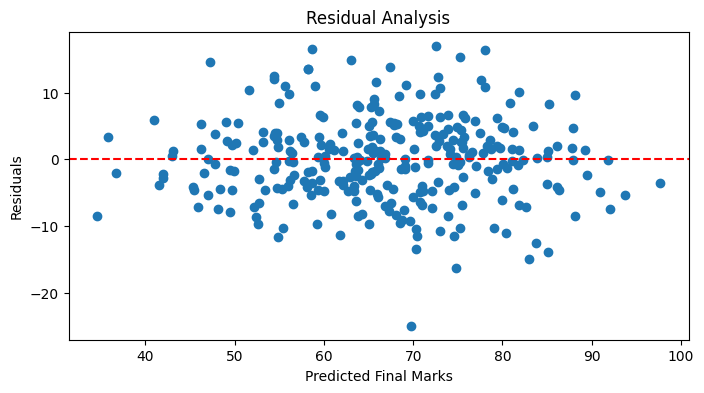

In [40]:
# Residual scatter plot
plt.figure(figsize=(8, 4))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Final Marks")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()

In [41]:
residuals.mean()

np.float64(-0.002974199866028285)

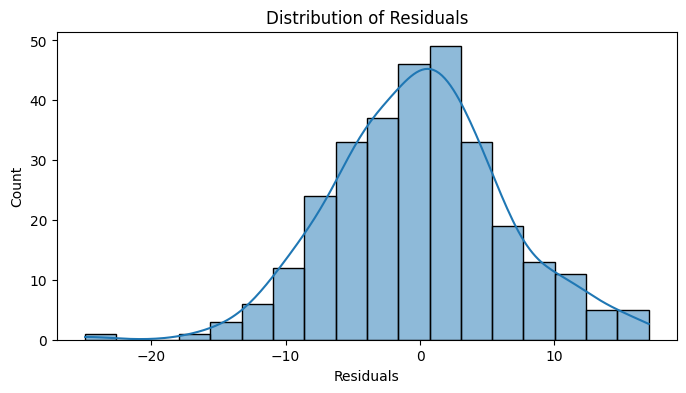

Mean Residual: -0.002974199866028285


In [42]:
plt.figure(figsize=(8, 4))
sns.histplot(residuals, kde=True)
plt.title("Distribution of Residuals")
plt.xlabel("Residuals")
plt.show()

print("Mean Residual:", residuals.mean())

In [43]:
# Model coefficients
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.named_steps["regressor"].coef_
})

print(coefficients)

         Feature  Coefficient
0     StudyHours     4.456065
1  AttendancePct     0.209838
2  PreviousScore     0.347650


In [44]:
# Model intercept
print("Intercept:", model.named_steps["regressor"].intercept_)

Intercept: 9.21138612623271


Baseline model

In [45]:
# Calculate average marks from training data
baseline_value = y_train.mean()

# Predict the same average for every test student
baseline_pred = np.full(len(y_test), baseline_value)

In [46]:
# Evaluate baseline
baseline_mae = mean_absolute_error(y_test, baseline_pred)

print("Baseline MAE:", baseline_mae)
print("Regression MAE:",mae)

Baseline MAE: 10.882600622787846
Regression MAE: 4.918147929684386


In [47]:
baseline_r2 = r2_score(y_test, baseline_pred)

print("Baseline R2:", baseline_r2)
print("Linear Regression R2:", r2)


Baseline R2: -0.0012232217474781315
Linear Regression R2: 0.7727438428263163


Model: **Decision Tree Regression**

In [48]:


# Create Decision Tree pipeline
tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("regressor", DecisionTreeRegressor(random_state=42))
])

# Train the model
tree_model.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer()),
                ('regressor', DecisionTreeRegressor(random_state=42))])

In [49]:
# Make predictions
tree_pred = tree_model.predict(X_test)

comparison_tree = pd.DataFrame({"Actual": y_test, "Predicted": tree_pred})
print(comparison_tree)

     Actual  Predicted
466    75.9       83.1
273    81.5       69.7
42     80.2       83.4
901    71.9       61.8
240    76.6       76.0
..      ...        ...
606    81.8       81.1
900    58.7       67.4
53     77.7       82.5
155    76.9       79.3
563    82.0       75.0

[298 rows x 2 columns]


In [50]:
tree_mae = mean_absolute_error(y_test, tree_pred)
tree_mse = mean_squared_error(y_test, tree_pred)
tree_rmse = np.sqrt(tree_mse)
tree_r2 = r2_score(y_test, tree_pred)

print("MAE:", tree_mae)
print("MSE:", tree_mse)
print("RMSE:", tree_rmse)
print("R2:", tree_r2)


MAE: 6.798322147651006
MSE: 77.25889261744967
RMSE: 8.789703784397384
R2: 0.5629116175059321


Conclusion: For this dataset and this train/test split, Linear Regression performs better.


In [51]:
# compare its training and testing performance

tree_train_pred = tree_model.predict(X_train)

tree_train_mae = mean_absolute_error(
    y_train,
    tree_train_pred
)

print("Training MAE:", tree_train_mae)
print("Testing MAE:", tree_mae)

Training MAE: 0.0
Testing MAE: 6.798322147651006


Reduce Decision Tree complexity

In [52]:
# Decision Tree with maximum depth 3
tree_model2 = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("regressor", DecisionTreeRegressor(max_depth=3, random_state=42))
])

tree_model2.fit(X_train, y_train)


Pipeline(steps=[('imputer', SimpleImputer()),
                ('regressor',
                 DecisionTreeRegressor(max_depth=3, random_state=42))])

In [53]:
# Generate predictions
tree2_train_pred = tree_model2.predict(X_train)
tree2_test_pred = tree_model2.predict(X_test)



In [54]:
# Calculate MAE for both

tree2_train_mae = mean_absolute_error(y_train, tree2_train_pred)
tree2_test_mae = mean_absolute_error(y_test, tree2_test_pred)

print("Training MAE:", tree2_train_mae)
print("Testing MAE:", tree2_test_mae)

Training MAE: 6.06183444533021
Testing MAE: 6.942310059286923


In [55]:
# Decision Tree with maximum depth 5
tree_model3 = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("regressor", DecisionTreeRegressor(max_depth=5, random_state=42))
])

tree_model3.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer()),
                ('regressor',
                 DecisionTreeRegressor(max_depth=5, random_state=42))])

In [56]:
# Generate predictions
tree3_train_pred = tree_model3.predict(X_train)
tree3_test_pred = tree_model3.predict(X_test)


In [57]:
# Calculate MAE for both

tree3_train_mae = mean_absolute_error(y_train, tree3_train_pred)
tree3_test_mae = mean_absolute_error(y_test, tree3_test_pred)

print("Training MAE:", tree3_train_mae)
print("Testing MAE:", tree3_test_mae)

Training MAE: 4.826234873294034
Testing MAE: 5.914348871320236


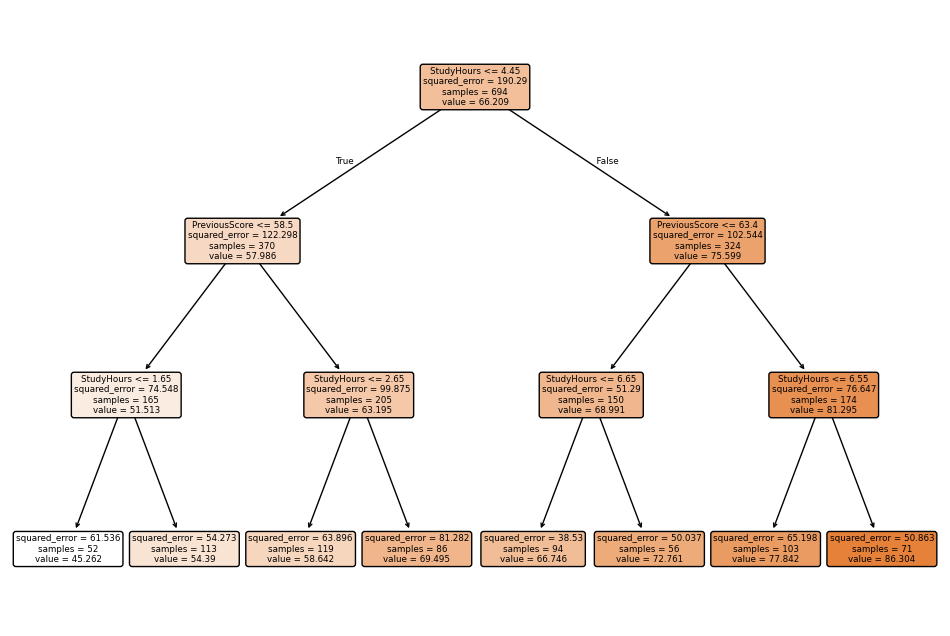

In [58]:
plt.figure(figsize=(12, 8))

plot_tree(
    tree_model2.named_steps["regressor"],
    feature_names=X.columns,
    filled=True,
    rounded=True
)

plt.show()

In [59]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree (Unlimited)",
        "Decision Tree (Depth 3)",
        "Decision Tree (Depth 5)"
    ],
    "Test MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, tree_pred),
        mean_absolute_error(y_test, tree2_test_pred),
        mean_absolute_error(y_test, tree3_test_pred)
    ]
})

model_comparison

,Model,Test MAE
0,Linear Regression,4.918148
1,Decision Tree (Unlimited),6.798322
2,Decision Tree (Depth 3),6.942310
3,Decision Tree (Depth 5),5.914349
